<center><h3>Predicting heacy-tailed income density from different models</h3></center>

**Goal:** learn the density curve from data and see when the estimate breaks down.

- The model gets **income** as input and learns the noisy **density** column.
- `true_density` is **never** given to a model during training. It is only used afterwards to score the predictions.
- Four ways to break the estimate: **too little data**, **too noisy data**, **wrong model**, **too few high earners** (the tail share `eps`).
- The default tail share is `eps = 0.025`. The experiments also try `eps = 0.01` and `eps = 0.05`.

#### 0. The true density and the data generator

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, SplineTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

In [2]:
eps, mu, sigma, lam, alpha = 0.025, 10.5, 0.5, 250_000, 1.5
## eps = share of people who come from the heavy tail. 0.025 is the default.
## It is an argument of f() and generate_data(), so it can be changed per dataset.

body = stats.lognorm(s=sigma, scale=np.exp(mu))   # ordinary earners
tail = stats.lomax(c=alpha, scale=lam)            # very high earners

def f(x, eps=eps):
    return (1 - eps) * body.pdf(x) + eps * tail.pdf(x)

def generate_data(n, noise=0.0, seed=None, path=None, eps=eps):
    """n incomes drawn from f. 'density' = f(income) times random error, 'true_density' = exact f(income).
    eps = share of high earners (changing it changes the true density too)."""
    r = np.random.default_rng(seed)
    in_tail = r.random(n) < eps
    income = body.rvs(size=n, random_state=r)
    income[in_tail] = tail.rvs(size=in_tail.sum(), random_state=r)
    true_density = f(income, eps)
    density = true_density * np.exp(noise * r.standard_normal(n))   # noise=0.1 is roughly 10 % error
    df = pd.DataFrame({"income": income, "density": density, "true_density": true_density})
    if path:
        df.to_csv(path, index=False)
    return df

#### 1. Data and train/test split

In [3]:
data = generate_data(10_000, noise=0.1, seed=1, path="income_data.csv")   # uses the default eps = 0.025
display(data.describe())
data.head(20)

,income,density,true_density
count,1.000000e+04,1.000000e+04,1.000000e+04
mean,6.166599e+04,1.611840e-05,1.604704e-05
std,1.179776e+06,7.693506e-06,7.461557e-06
min,1.447906e+03,3.411307e-14,3.181861e-14
25%,2.596063e+04,1.029999e-05,1.029331e-05
50%,3.648270e+04,1.784627e-05,1.806527e-05
75%,5.135491e+04,2.238553e-05,2.285236e-05
max,1.165127e+08,3.329558e-05,2.438864e-05


,income,density,true_density
0,40856.521116,0.000016,0.000019
1,45943.137264,0.000015,0.000015
2,43541.411728,0.000017,0.000017
3,59375.710180,0.000008,0.000008
4,46272.592114,0.000015,0.000015
5,59531.048525,0.000008,0.000008
6,25576.647723,0.000022,0.000024
7,71089.691385,0.000004,0.000005
8,46585.628464,0.000014,0.000015
9,29626.360150,0.000023,0.000024


In [4]:
X = data[["income"]]            # the only input the models get
y = data["density"]             # the noisy target the models are trained on
truth = data["true_density"]    # only for scoring, never passed to fit()

assert "true_density" not in X.columns

X_train, X_test, y_train, y_test, _, truth_test = train_test_split(
    X, y, truth, test_size=0.25, random_state=42
)

X_train.shape, X_test.shape

## truth_train is thrown away (the "_"), so the training code cannot touch it

((7500, 1), (2500, 1))

#### 2. How we score a model

Every score compares the prediction to the **true** density, not to the noisy one. The true density depends on `eps`, so `score()` and `plot_fits()` must be given the same `eps` the data was generated with.

- `mse`, `r2`: the usual metrics on the test set (as in the template). Because almost everyone is in the body, these mostly measure the body.
- `body_factor`, `tail_factor`: on a fixed grid of incomes (3,000 to 10,000,000, evenly spaced on a log scale), how many times too high or too low is the prediction on average? **1.0 is perfect, 2.0 means typically off by a factor of 2.** Body is incomes from 10k to 150k, tail is 250k and above. (Below 10k the true density has a small flat shelf, because the smooth tail component also puts a handful of people at very low incomes. It is left out of both scores.) Negative predictions are replaced by a tiny positive number, so they count as very wrong.
- `tail_250k_1M`, `tail_1M_plus`: the tail score split into two zones. The far tail (1M and up) has the least data, so it is the first to break.

In [5]:
grid = np.logspace(np.log10(3_000), 7, 400)
GRID = pd.DataFrame({"income": grid})
body_part = (grid >= 10_000) & (grid < 150_000)
tail_part = grid >= 250_000
tail_mid  = (grid >= 250_000) & (grid < 1_000_000)   # tail zone 1: 250k to 1M
tail_far  = grid >= 1_000_000                        # tail zone 2: 1M and up (hardest, almost no data)

def factor_off(pred, true):
    pred = np.clip(pred, 1e-15, None)
    return 10 ** np.mean(np.abs(np.log10(pred / true)))

def score(model, X_test, truth_test, eps=eps):
    # eps must match the eps the data was generated with, because the true curve depends on it
    true_grid = f(grid, eps)
    pred_test = model.predict(X_test)
    pred_grid = model.predict(GRID)
    return {
        "mse": mean_squared_error(truth_test, pred_test),
        "r2": r2_score(truth_test, pred_test),
        "body_factor": factor_off(pred_grid[body_part], true_grid[body_part]),
        "tail_factor": factor_off(pred_grid[tail_part], true_grid[tail_part]),
        "tail_250k_1M": factor_off(pred_grid[tail_mid], true_grid[tail_mid]),
        "tail_1M_plus": factor_off(pred_grid[tail_far], true_grid[tail_far]),
    }

def plot_fits(models, X_tr, y_tr, title="", eps=eps):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    g_lin = np.linspace(1_000, 150_000, 400)
    for a, g, logscale in [(ax[0], g_lin, False), (ax[1], grid, True)]:
        a.scatter(X_tr["income"], y_tr, s=2, alpha=0.15, color="gray", label="training data")
        a.plot(g, f(g, eps), "k", lw=2, label="true density")
        for name, m in models.items():
            p = m.predict(pd.DataFrame({"income": g}))
            a.plot(g, np.clip(p, 1e-15, None) if logscale else p, label=name)
        if logscale:
            a.set_xscale("log"); a.set_yscale("log"); a.set_ylim(1e-13, 1e-4)
        else:
            a.set_xlim(0, 150_000); a.set_ylim(-1e-5, 4e-5)
        a.set_xlabel("Income (€)"); a.set_ylabel("Density")
    ax[0].legend(); fig.suptitle(title); plt.show()

#### 3. Plain OLS

`density = a + b * income`. A straight line. It is only a reference point and is not part of the later comparison.

In [6]:
ols_raw = LinearRegression()
ols_raw.fit(X_train, y_train)

ols_raw.coef_, ols_raw.intercept_, score(ols_raw, X_test, truth_test)

## coef_ and intercept_ are the model parameters, no hyperparameters here
## the density is a hill, a straight line cannot follow a hill

(array([-2.85096067e-13]),
 np.float64(1.6173104056781565e-05),
 {'mse': 5.547656763093104e-11,
  'r2': 0.0012749978051398436,
  'body_factor': np.float64(3.18541058944359),
  'tail_factor': np.float64(17871.188896792384),
  'tail_250k_1M': np.float64(1720.1843549776847),
  'tail_1M_plus': np.float64(72199.39767322996)})

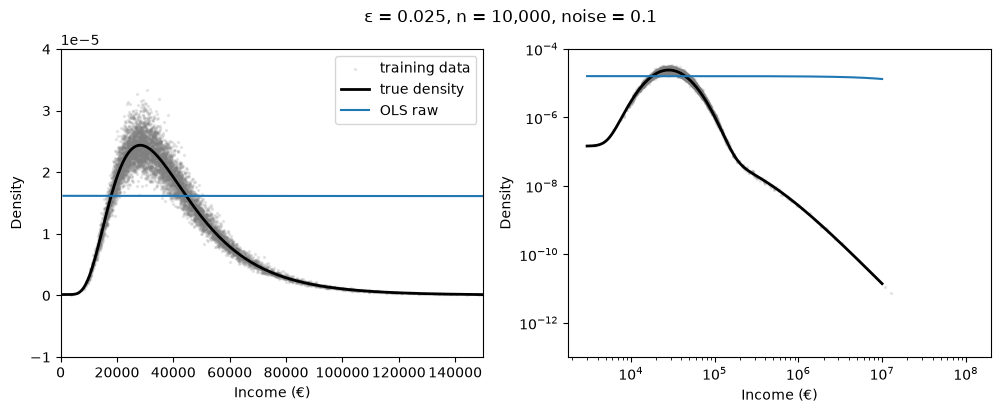

In [7]:
plot_fits({"OLS raw": ols_raw}, X_train, y_train, "ε = 0.025, n = 10,000, noise = 0.1")

## left: the normal view, right: the log-log view

#### 4. Beyond OLS: nonlinear models

Plain OLS fails because a straight line is the wrong shape for a hill. Three ways to get a more flexible shape:

**Spline regression.** Glue together small cubic curves at a few "knots", so the curve can bend where it needs to. It is still linear regression underneath (the model is a weighted sum of fixed bendy building blocks), so it is fast and has no randomness. Beyond the last data point we let it continue in a straight line *in the log-log view*, which is exactly what a Pareto-type tail looks like.

**k-nearest neighbors.** To predict the density at some income, find the 15 training people with the closest incomes and average their density values. No formula is assumed at all. Outside the range of the data it has nobody to ask except the outermost points, so it goes flat.

**Gradient boosting.** Build many small decision trees, each one fixing the mistakes of the ones before it. A tree predicts step-shaped curves (a constant in each income bracket). Like k-NN, it goes flat outside the data.

**Why every model works in logs.** The density spans about 7 orders of magnitude. On the raw scale a tail error of 1e-9 is invisible next to body values of 1e-5, so a model trained on raw values would simply ignore the tail. In logs, being 10 times too low counts the same in the body and in the tail.

The settings you choose by hand (number of knots, number of neighbors, number of trees, learning rate) are the **hyperparameters**. Below they are fixed at reasonable defaults; tuning them with `GridSearchCV` as in the template is a natural next step.

In [8]:
def in_logs(regressor):
    # fit on log(density), then turn predictions back with exp
    return TransformedTargetRegressor(regressor=regressor, func=np.log, inverse_func=np.exp)

def make_spline():
    return in_logs(Pipeline([
        ("log_x", FunctionTransformer(np.log)),
        ("spline", SplineTransformer(n_knots=8, degree=3, knots="quantile", extrapolation="linear")),
        ("ols", LinearRegression()),
    ]))

def make_knn():
    return in_logs(Pipeline([
        ("log_x", FunctionTransformer(np.log)),
        ("knn", KNeighborsRegressor(n_neighbors=15)),
    ]))

def make_boost():
    # trees only compare sizes of incomes, so taking log(income) would change nothing here
    return in_logs(HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1))

makers = {"Spline OLS": make_spline, "k-NN": make_knn, "Gradient boosting": make_boost}

#### 5. Fitting the three models on one dataset

In [9]:
## the data from section 1: n = 10,000, noise = 0.1, eps = 0.025 (the default)
fitted = {name: make().fit(X_train, y_train) for name, make in makers.items()}

pd.DataFrame({name: score(m, X_test, truth_test) for name, m in fitted.items()}).T

,mse,r2,body_factor,tail_factor,tail_250k_1M,tail_1M_plus
Spline OLS,4.424205e-13,0.992035,1.086795,1.346143,1.354964,1.340909
k-NN,2.024078e-13,0.996356,1.022828,2.319830,1.046287,3.730148
Gradient boosting,9.643692e-14,0.998264,1.038939,3.888521,2.170516,5.505906


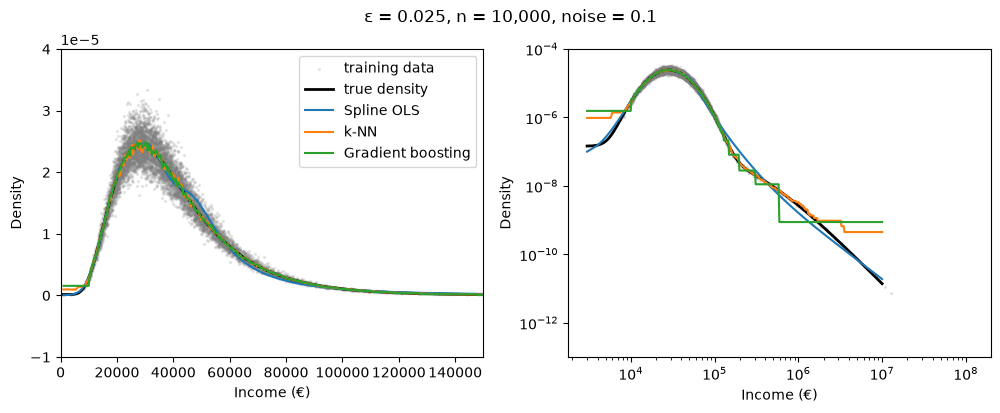

In [10]:
plot_fits(fitted, X_train, y_train, "ε = 0.025, n = 10,000, noise = 0.1")

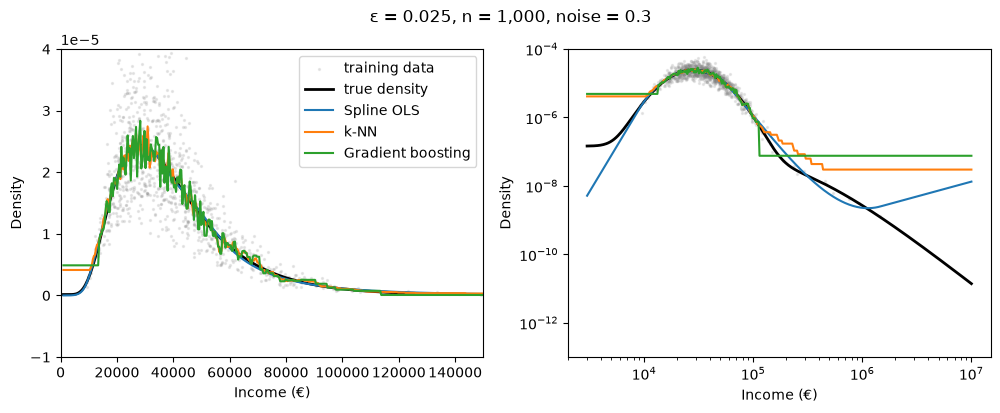

In [11]:
## a small dataset: only about 25 of the 1,000 people are high earners
small = generate_data(1_000, noise=0.3, seed=3)
fitted_small = {name: make().fit(small[["income"]], small["density"]) for name, make in makers.items()}
plot_fits(fitted_small, small[["income"]], small["density"], "ε = 0.025, n = 1,000, noise = 0.3")

#### 6. Breaking it on purpose

For every combination of tail share `eps` (0.01, 0.025, 0.05), data size (1,000 to 1,000,000) and noise level (0, 0.1, 0.3, 1.0) we generate fresh data 10 times, fit the three models, and take the **median** score. Each fit only sees `income` and `density`. The score for each setting uses the true density for that setting's own `eps`.

The sweep fits 3 models on 480 datasets, so it takes several minutes (it runs in parallel).

In [23]:
import warnings
warnings.filterwarnings("ignore")

def one_run(model_makers, n, noise, e, seed, rep):
    d = generate_data(n, noise, seed=seed, eps=e)
    Xtr, Xte, ytr, yte, _, tte = train_test_split(
        d[["income"]], d["density"], d["true_density"], test_size=0.25, random_state=rep
    )
    rows = []
    for name, make in model_makers.items():
        m = make().fit(Xtr, ytr)          # sees only income and the noisy density
        rows.append({"model": name, "eps": e, "n": n, "noise": noise, **score(m, Xte, tte, eps=e)})
    return rows

def run_sweep(model_makers, sizes=(1_000, 10_000, 100_000), noises=(0.0, 0.1, 0.3, 0.5, 0.8, 1.0),
              epss=(0.01, 0.025, 0.05), repeats=10, n_jobs=2):
    master = np.random.default_rng(0)   # same seed on every call, so every model is tested on the very same datasets
    jobs = []
    for n in sizes:
        for noise in noises:
            for rep in range(repeats):
                seed = int(master.integers(1e9))
                for e in epss:
                    jobs.append((n, noise, e, seed, rep))
    out = Parallel(n_jobs=n_jobs)(delayed(one_run)(model_makers, *j) for j in jobs)
    return pd.DataFrame([row for rows in out for row in rows])

results = run_sweep(makers)

In [24]:
def table(metric, df):
    return df.pivot_table(index=["model", "eps", "n"], columns="noise", values=metric, aggfunc="median")

table("body_factor", results).round(2)

noise                            0.0   0.1   0.3   0.5   0.8   1.0
model             eps   n                                         
Gradient boosting 0.010 1000    1.20  1.24  1.30  1.34  1.39  1.51
                        10000   1.04  1.05  1.07  1.10  1.14  1.18
                        100000  1.04  1.04  1.05  1.05  1.06  1.07
                  0.025 1000    1.26  1.33  1.29  1.36  1.47  1.58
                        10000   1.03  1.04  1.07  1.09  1.13  1.16
                        100000  1.03  1.04  1.04  1.04  1.05  1.06
                  0.050 1000    1.14  1.11  1.17  1.23  1.39  1.48
                        10000   1.03  1.04  1.06  1.08  1.14  1.16
                        100000  1.03  1.03  1.03  1.04  1.05  1.05
Spline OLS        0.010 1000    1.04  1.04  1.04  1.05  1.09  1.11
                        10000   1.07  1.07  1.07  1.07  1.08  1.09
                        100000  1.08  1.09  1.09  1.09  1.08  1.09
                  0.025 1000    1.07  1.08  1.08  1.09  1.13  1.15
                        10000   1.08  1.09  1.09  1.09  1.09  1.11
                        100000  1.11  1.10  1.11  1.11  1.11  1.11
                  0.050 1000    1.08  1.08  1.08  1.09  1.10  1.11
                        10000   1.09  1.09  1.10  1.09  1.09  1.10
                        100000  1.11  1.11  1.11  1.11  1.11  1.11
k-NN              0.010 1000    1.09  1.11  1.13  1.18  1.23  1.29
                        10000   1.00  1.02  1.06  1.11  1.17  1.23
                        100000  1.00  1.02  1.07  1.10  1.18  1.24
                  0.025 1000    1.08  1.10  1.12  1.15  1.21  1.27
                        10000   1.00  1.02  1.07  1.11  1.18  1.23
                        100000  1.00  1.02  1.06  1.10  1.17  1.22
                  0.050 1000    1.06  1.08  1.11  1.16  1.19  1.22
                        10000   1.00  1.02  1.06  1.11  1.18  1.23
                        100000  1.00  1.02  1.06  1.11  1.18  1.23

In [25]:
table("tail_factor", results).round(2)

noise                              0.0     0.1     0.3     0.5     0.8     1.0
model             eps   n                                                     
Gradient boosting 0.010 1000    637.08  465.08  571.79  399.98  534.80  668.28
                        10000    11.57   11.52    9.56   10.65   12.08   10.48
                        100000   11.18   10.98   10.49   11.30   11.32   10.85
                  0.025 1000    123.55   56.06   86.58   49.30   84.90   79.05
                        10000     4.71    4.18    3.78    4.42    4.57    4.06
                        100000    4.29    4.21    4.35    4.51    4.10    4.45
                  0.050 1000     22.70   12.06   20.17   17.36   17.63   13.61
                        10000     2.63    2.37    2.52    2.79    2.59    2.47
                        100000    2.45    2.50    2.52    2.58    2.46    2.51
Spline OLS        0.010 1000      6.70   19.59   49.91   91.60   34.80    9.46
                        10000     3.45    6.88    3.72    4.82    2.82    3.24
                        100000    2.01    2.10    2.05    1.98    2.02    2.16
                  0.025 1000      6.39    2.13    8.07    2.25    5.66    3.06
                        10000     1.76    1.71    1.37    1.61    1.55    1.45
                        100000    1.39    1.37    1.37    1.38    1.34    1.38
                  0.050 1000      1.77    1.30    2.16    1.65    1.43    2.51
                        10000     1.23    1.30    1.24    1.31    1.24    1.33
                        100000    1.33    1.31    1.29    1.33    1.27    1.33
k-NN              0.010 1000    419.90  287.53  369.83  237.52  325.18  393.13
                        10000     5.06    5.66    4.55    5.27    6.35    5.14
                        100000    1.22    1.25    1.25    1.32    1.34    1.41
                  0.025 1000     68.57   29.94   50.48   31.56   53.41   50.77
                        10000     2.62    2.33    2.17    2.49    2.56    2.37
                        100000    1.05    1.08    1.09    1.13    1.20    1.23
                  0.050 1000     15.25    7.67   13.81   13.39   11.98    9.85
                        10000     1.63    1.61    1.68    1.73    1.73    1.81
                        100000    1.02    1.04    1.07    1.12    1.19    1.24

In [26]:
table("tail_250k_1M", results).round(2)

noise                             0.0    0.1    0.3    0.5    0.8    1.0
model             eps   n                                               
Gradient boosting 0.010 1000    58.60  42.78  52.59  36.79  49.19  61.47
                        10000    1.87   2.04   1.91   1.99   1.92   2.00
                        100000   1.91   1.93   2.00   1.90   1.90   1.95
                  0.025 1000    11.43   5.19   8.01   4.56   7.85   7.31
                        10000    1.72   1.63   1.66   1.86   1.92   1.92
                        100000   1.87   1.88   1.87   1.88   1.90   1.83
                  0.050 1000     2.20   1.88   2.07   2.16   1.89   1.93
                        10000    1.21   1.19   1.20   1.27   1.30   1.24
                        100000   1.20   1.20   1.19   1.20   1.20   1.20
Spline OLS        0.010 1000     2.05   1.92   2.22   2.11   3.06   2.37
                        10000    1.92   1.79   1.70   1.88   1.89   1.71
                        100000   1.68   1.72   1.69   1.67   1.69   1.67
                  0.025 1000     1.69   1.44   1.68   1.59   1.47   1.70
                        10000    1.43   1.40   1.34   1.37   1.43   1.38
                        100000   1.36   1.34   1.35   1.35   1.34   1.36
                  0.050 1000     1.32   1.22   1.28   1.28   1.33   1.20
                        10000    1.22   1.22   1.20   1.22   1.20   1.21
                        100000   1.25   1.24   1.24   1.24   1.24   1.24
k-NN              0.010 1000    48.08  32.59  34.11  22.32  34.57  37.78
                        10000    1.22   1.17   1.22   1.21   1.28   1.33
                        100000   1.01   1.03   1.06   1.10   1.16   1.23
                  0.025 1000     7.83   4.26   5.62   4.24   7.12   6.96
                        10000    1.06   1.05   1.10   1.10   1.17   1.17
                        100000   1.00   1.02   1.06   1.11   1.18   1.23
                  0.050 1000     1.82   1.40   1.77   2.04   1.87   1.57
                        10000    1.03   1.03   1.06   1.11   1.20   1.21
                        100000   1.00   1.02   1.06   1.10   1.19   1.23

In [27]:
table("tail_1M_plus", results).round(2)

noise                               0.0      0.1      0.3      0.5      0.8  \
model             eps   n                                                     
Gradient boosting 0.010 1000    2644.59  1930.60  2373.54  1660.34  2219.98   
                        10000     34.27    33.94    24.35    29.09    37.08   
                        100000    32.10    30.94    28.16    32.79    32.88   
                  0.025 1000     511.09   231.92   358.16   203.94   351.22   
                        10000      8.45     7.10     6.31     7.42     7.67   
                        100000     7.04     6.78     7.25     7.60     6.69   
                  0.050 1000      91.35    37.32    79.44    65.49    66.83   
                        10000      4.08     3.57     3.97     4.49     3.88   
                        100000     3.76     3.89     3.94     4.06     3.79   
Spline OLS        0.010 1000      14.29    71.94   375.41   612.51    79.53   
                        10000      4.97    14.43     5.59     8.33     3.53   
                        100000     2.26     2.36     2.29     2.20     2.24   
                  0.025 1000      13.27     2.64    22.67     3.07     8.88   
                        10000      2.00     1.91     1.40     1.79     1.65   
                        100000     1.41     1.38     1.38     1.40     1.34   
                  0.050 1000       2.18     1.29     2.98     1.92     1.65   
                        10000      1.24     1.35     1.26     1.39     1.29   
                        100000     1.38     1.36     1.32     1.38     1.30   
k-NN              0.010 1000    1579.62  1111.98  1532.70   985.95  1342.25   
                        10000     11.72    14.52    10.04    12.61    16.64   
                        100000     1.36     1.40     1.38     1.46     1.42   
                  0.025 1000     264.91   103.64   185.25   111.51   182.82   
                        10000      4.50     3.76     3.24     3.96     4.07   
                        100000     1.08     1.12     1.10     1.14     1.20   
                  0.050 1000      54.13    21.34    46.88    42.97    35.99   
                        10000      2.15     2.10     2.20     2.26     2.19   
                        100000     1.04     1.05     1.07     1.13     1.19   

noise                               1.0  
model             eps   n                
Gradient boosting 0.010 1000    2774.10  
                        10000     28.11  
                        100000    30.21  
                  0.025 1000     327.00  
                        10000      6.50  
                        100000     7.26  
                  0.050 1000      45.81  
                        10000      3.81  
                        100000     3.90  
Spline OLS        0.010 1000      18.21  
                        10000      4.76  
                        100000     2.49  
                  0.025 1000       3.92  
                        10000      1.48  
                        100000     1.40  
                  0.050 1000       3.46  
                        10000      1.40  
                        100000     1.39  
k-NN              0.010 1000    1435.38  
                        10000     11.26  
                        100000     1.53  
                  0.025 1000     165.00  
                        10000      3.65  
                        100000     1.22  
                  0.050 1000      30.60  
                        10000      2.28  
                        100000     1.25

In [28]:
table("r2", results).round(3)

noise                              0.0    0.1    0.3    0.5    0.8    1.0
model             eps   n                                                
Gradient boosting 0.010 1000     0.997  0.987  0.922  0.778  0.353  0.008
                        10000    1.000  0.998  0.985  0.955  0.878  0.820
                        100000   1.000  1.000  0.999  0.997  0.994  0.992
                  0.025 1000     0.997  0.989  0.925  0.756  0.501  0.109
                        10000    1.000  0.998  0.984  0.955  0.897  0.829
                        100000   1.000  1.000  0.999  0.998  0.994  0.990
                  0.050 1000     0.997  0.988  0.926  0.783  0.499  0.171
                        10000    1.000  0.998  0.986  0.959  0.895  0.843
                        100000   1.000  1.000  0.999  0.998  0.994  0.991
Spline OLS        0.010 1000     0.999  0.998  0.995  0.988  0.971  0.955
                        10000    0.996  0.997  0.996  0.997  0.992  0.993
                        100000   0.992  0.994  0.994  0.992  0.991  0.991
                  0.025 1000     0.997  0.997  0.992  0.986  0.974  0.958
                        10000    0.994  0.991  0.991  0.992  0.992  0.985
                        100000 -22.877  0.987  0.984  0.986  0.981  0.986
                  0.050 1000     0.996  0.996  0.992  0.984  0.975  0.983
                        10000    0.991  0.984  0.986  0.990  0.990  0.986
                        100000   0.978  0.982  0.979  0.975  0.980  0.979
k-NN              0.010 1000     1.000  0.995  0.964  0.911  0.723  0.567
                        10000    1.000  0.996  0.967  0.902  0.749  0.588
                        100000   1.000  0.996  0.965  0.902  0.734  0.563
                  0.025 1000     1.000  0.996  0.964  0.898  0.765  0.660
                        10000    1.000  0.996  0.966  0.910  0.771  0.587
                        100000   1.000  0.996  0.967  0.908  0.749  0.582
                  0.050 1000     0.999  0.995  0.967  0.921  0.794  0.627
                        10000    1.000  0.997  0.970  0.913  0.773  0.627
                        100000   1.000  0.997  0.969  0.912  0.768  0.622

#### 7. The tail share `eps`: the same data size, three populations

The tail is hard because of **how many tail people the model gets to see**. Roughly, the number of training points above income x is `n * eps * (1 + x/250,000)^-1.5`. Expected counts above 250k:

| n | eps = 0.01 | eps = 0.025 | eps = 0.05 |
|---|---|---|---|
| 1,000 | about 4 | about 9 | about 18 |
| 10,000 | about 35 | about 90 | about 180 |
| 100,000 | about 350 | about 900 | about 1,800 |
| 1,000,000 | about 3,500 | about 9,000 | about 18,000 |

(Expected counts, so fuzzy in a single dataset. Above 1M the counts are about 11 times smaller still.)

Raising `eps` changes the true density too, so it is not the same problem made easier. It is a different, heavier-tailed population. Below, the same models are fitted on 10,000 observations with 10 % noise for each of the three values.

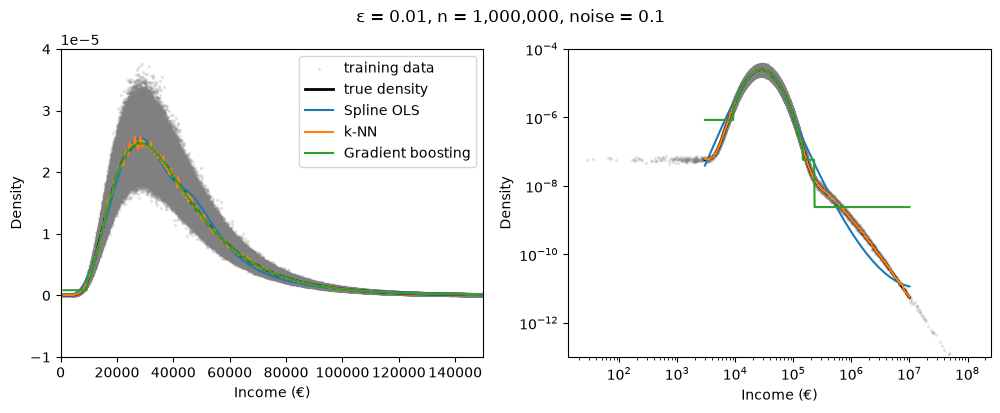

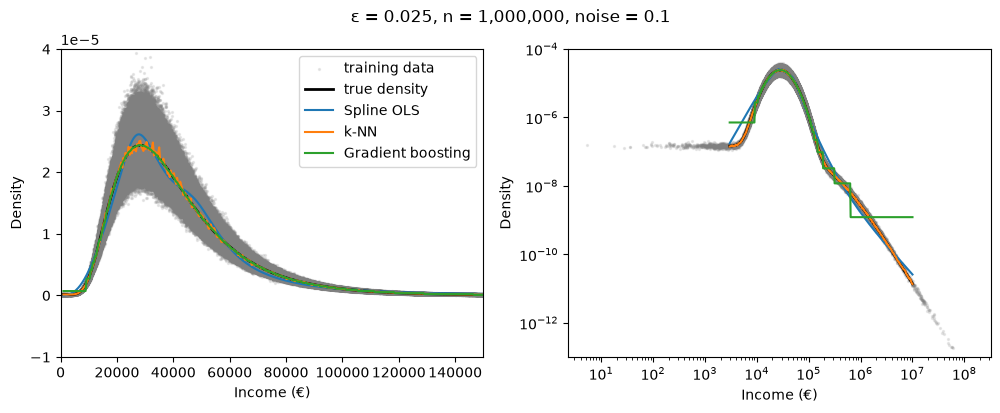

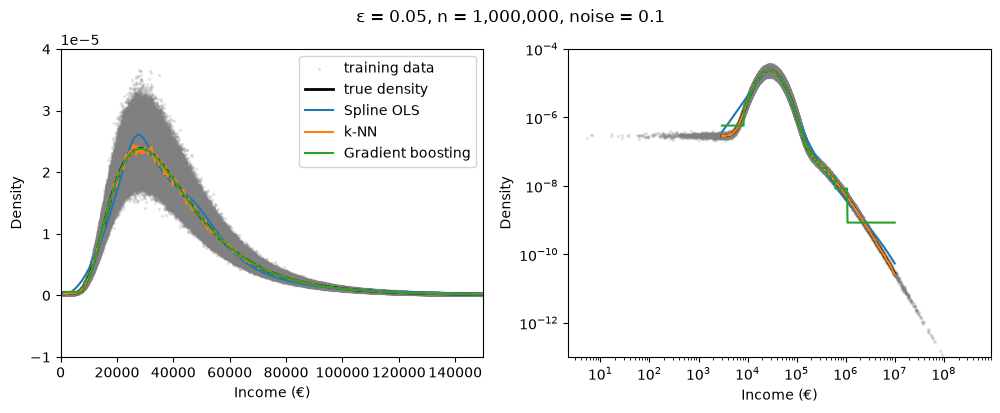

In [33]:
for e in (0.01, 0.025, 0.05):
    d = generate_data(1_000_000, noise=0.1, seed=11, eps=e)
    fits = {name: make().fit(d[["income"]], d["density"]) for name, make in makers.items()}
    plot_fits(fits, d[["income"]], d["density"], f"ε = {e}, n = 1,000,000, noise = 0.1", eps=e)

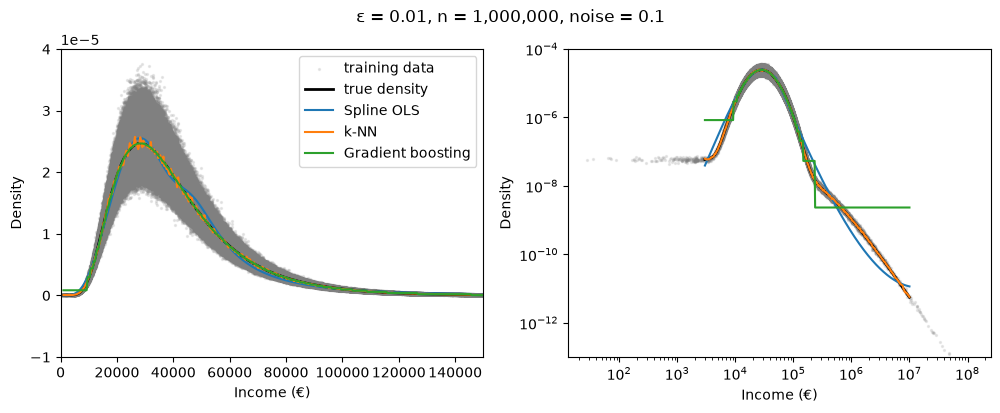

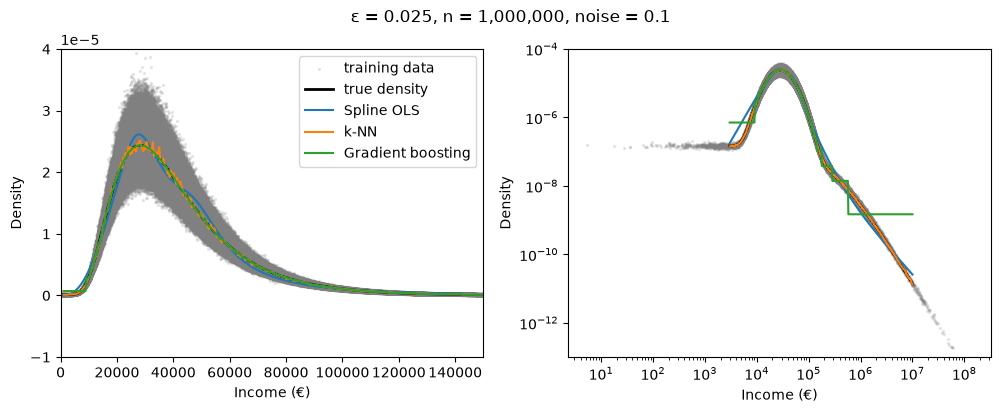

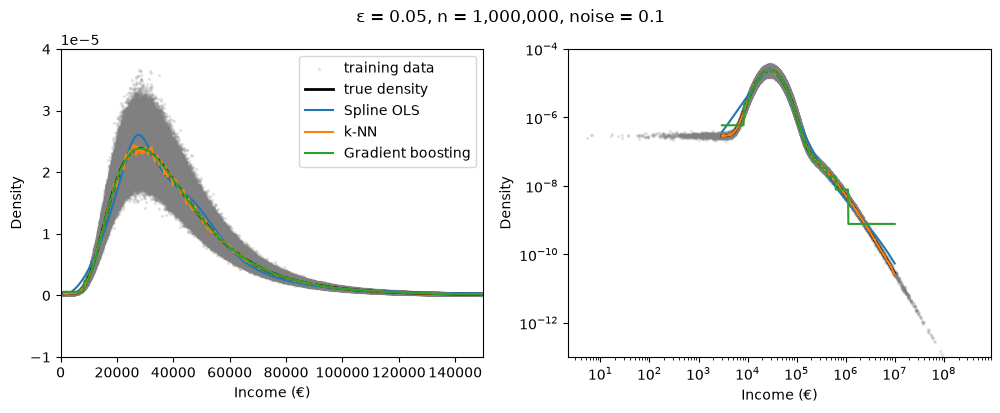

In [32]:
for e in (0.01, 0.025, 0.05):
    d = generate_data(1_000_000, noise=0.1, seed=11, eps=e)
    fits = {name: make().fit(d[["income"]], d["density"]) for name, make in makers.items()}
    plot_fits(fits, d[["income"]], d["density"], f"ε = {e}, n = 1,000,000, noise = 0.1", eps=e)

#### 8. Reading the results

All scores are medians over 10 datasets. Because each `eps` is a different true density, compare models within the same `eps`.

**Body.** The body is easy for everyone. With 10,000 or more observations the spline is within about 8 to 12 % of the true density, k-NN within about 2 % (6 % at noise 0.3) and gradient boosting within about 3 to 7 %. At n = 1,000 boosting is about 1.2 to 1.3 times off, because trees chop a small dataset into coarse steps.

**Tail.** The number of tail people decides everything, and `eps` and n trade off against each other.
- At n = 1,000 the local models lose the tail: at `eps = 0.025` and noise 0.1 k-NN is about 100 times off and boosting about 230 times (`tail_factor`, 250k and up). The spline's straight-line tail copes better (about 2.6 times), but it is erratic at this size, see below.
- At n = 10,000 and `eps = 0.025` the tail error is about 1.4 (spline), 3.5 (k-NN) and 6 to 8 (boosting) in the far tail.
- The same data size at `eps = 0.01` is clearly worse (spline about 3, k-NN about 13, boosting about 34) and at `eps = 0.05` clearly better (about 1.2, 2.1 and 4).
- With 100,000 or more observations k-NN reaches 1.0 to 1.8 times everywhere, even at `eps = 0.01`.

**More data does not fix a wrong model.** Spline and boosting stop improving after n = 10,000 to 100,000. Boosting stays about 7 times off in the far tail at `eps = 0.025`, even at a million observations, because trees go flat beyond the largest income they have seen. The spline plateaus at about 1.4 for the same reason in reverse: its straight-line tail is close but not exactly right. Only k-NN keeps improving with n (about 1.0 at a million observations).

**Noise.** The body score of the spline barely changes with noise. k-NN and boosting chase the scatter, so their body error grows with noise (k-NN about 1.02 to 1.23 at n = 10,000 as noise goes from 0.1 to 1.0), and k-NN's R² stays around 0.55 to 0.65 at noise 1.0 whatever the data size. Boosting at n = 1,000 and noise 1.0 has R² of about 0. Noise matters most where tail data is scarce: at `eps = 0.01` and n = 1,000 the spline's tail error grows from about 14 with no noise to about 1,850 at noise 1.0.

**Single-run caution for small n.** At n = 1,000 the tail scores jump around between noise levels (for example the spline at `eps = 0.025`: 13, 2.6, 23, 2.3 for noise 0, 0.1, 0.3, 1.0), because the tail comes from a handful of people and the datasets differ. Treat these cells as "roughly tens of times off", not as exact values.

**Warning about R².** For the spline at n = 1,000,000 some medians of R² are hugely negative (for example about -6.6e8 at `eps = 0.025`, noise 0). In the one case I inspected, the worst predictions were at incomes of a few tens of euros, below the lowest income in the training data (the tail component creates a few such people), where the spline's straight-line continuation overshoots. Squared-error metrics like R² are dominated by such points, which is another reason to report the factor scores.